# Deep Learning - zadania 1-10: rozwiązania

__Kiedy wykonać:__ po przerobieniu notatnika `03_Jak_ucza_sie_sieci_spadek_gradientu.ipynb` (rozdział 5), czyli po trzech pierwszych notatnikach:

- zadania 1-3 - `01_Podstawy_sieci_neuronowych_MLP.ipynb`,
- zadania 4-8 - `02_Podstawowe_komponenty_sieci.ipynb`,
- zadania 9-10 - `03_Jak_ucza_sie_sieci_spadek_gradientu.ipynb`.

Część zadań ma kilka równoważnych rozwiązań - poniżej pokazano jedno z nich.

### Import bibliotek i dane

In [1]:
import numpy as np
from sklearn.datasets import make_moons
from sklearn.neural_network import MLPClassifier
from tensorflow import keras

Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 3 ("axes.prop_cycle: cycler('color', ['#123D98', '#C21E3C', '#E2A713', '#00AEEF', '#7F3F98'])"): Key axes.prop_cycle: "cycler('color', ['" is not a valid cycler construction: Could not parse "cycler('color', ['": unterminated string literal (detected at line 1) (<unknown>, line 1)
Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 6 ('grid.color: #e0e0e0'): Key grid.color: '' does not look like a color arg


### Ćwiczenie 1
Sztuczny neuron ma trzy wejścia, wagi i bias:
`x = [2.0, -1.0, 0.5]`, `w = [0.4, 0.3, -0.2]`, `b = 0.1`.

Oblicz **sumę ważoną** `z = w·x + b`, a następnie wyjście neuronu z funkcją aktywacji **sigmoid**. Wydrukuj obie wartości, zaokrąglone do 4 miejsc po przecinku.

__Oczekiwany wynik:__

```
0.5
0.6225
```

__Wskazówka:__ Iloczyn skalarny: `np.dot(w, x)`. Sigmoid: $1 / (1 + e^{-z})$.

In [2]:
x = np.array([2.0, -1.0, 0.5])
w = np.array([0.4, 0.3, -0.2])
b = 0.1

In [3]:
z = np.dot(w, x) + b
a = 1 / (1 + np.exp(-z))
print(round(z, 4))
print(round(a, 4))

0.5
0.6225


### Ćwiczenie 2
Lista `layer_sizes` opisuje sieć: 10 cech wejściowych, dwie warstwy ukryte (64 i 32 neurony) i 1 neuron wyjściowy.

Policz liczbę parametrów **każdej** warstwy gęstej wg wzoru `(n_in + 1) * n_out` oraz **łączną** liczbę parametrów sieci. Wydrukuj liczby w osobnych liniach: parametry kolejnych warstw, a na końcu sumę.

__Oczekiwany wynik:__

```
704
2080
33
2817
```

__Wskazówka:__ Pary (wejścia, wyjścia) kolejnych warstw dostaniesz z `zip(layer_sizes[:-1], layer_sizes[1:])`.

In [4]:
layer_sizes = [10, 64, 32, 1]

In [5]:
params = [(n_in + 1) * n_out for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:])]
for p in params:
    print(p)
print(sum(params))

704
2080
33
2817


In [8]:
layer_sizes[:-1]

[10, 64, 32]

In [10]:
layer_sizes[1:]

[64, 32, 1]

In [15]:
list(zip(layer_sizes[:-1], layer_sizes[1:]))

[(10, 64), (64, 32), (32, 1)]

In [6]:
[(n_in + 1) * n_out for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:])]

[704, 2080, 33]

### Ćwiczenie 3
Zbiór `images` zawiera 32 obrazy w skali szarości o rozmiarze 28x28 (batch), a `W` i `b` to wagi i bias warstwy gęstej z 10 neuronami.

1. Wydrukuj `ndim` i `shape` tablicy `images`.
2. „Spłaszcz” obrazy do wektorów (tak jak robi to warstwa `Flatten`) i wydrukuj nowy kształt.
3. Oblicz wyjście warstwy gęstej `Z = X @ W + b` dla spłaszczonych obrazów i wydrukuj kształt `Z`.

__Oczekiwany wynik:__

```
3 (32, 28, 28)
(32, 784)
(32, 10)
```

__Wskazówka:__ `reshape(32, -1)` automatycznie wylicza drugi wymiar.

In [18]:
images = np.random.default_rng(0).random((32, 28, 28))
W = np.random.default_rng(1).normal(size=(784, 10))
b = np.zeros(10)

In [21]:
print(images.ndim, images.shape)
X = images.reshape(32, -1)
print(X.shape)
Z = X @ W + b
print(Z.shape)

3 (32, 28, 28)
(32, 784)
(32, 10)


### Ćwiczenie 4
Dla wektora `z` oblicz wartości funkcji aktywacji **ReLU**, **sigmoid** i **tanh** (zaimplementuj je w NumPy). Wydrukuj trzy tablice w osobnych liniach, zaokrąglone do 3 miejsc po przecinku.

__Oczekiwany wynik:__

```
[0. 0. 0. 1. 3.]
[0.047 0.269 0.5   0.731 0.953]
[-0.995 -0.762  0.     0.762  0.995]
```

__Wskazówka:__ ReLU: `np.maximum(0, z)`. Tanh jest dostępny jako `np.tanh`.

In [22]:
z = np.array([-3.0, -1.0, 0.0, 1.0, 3.0])

In [23]:
relu = np.maximum(0, z)
sigmoid = 1 / (1 + np.exp(-z))
tanh = np.tanh(z)
print(relu.round(3))
print(sigmoid.round(3))
print(tanh.round(3))

[0. 0. 0. 1. 3.]
[0.047 0.269 0.5   0.731 0.953]
[-0.995 -0.762  0.     0.762  0.995]


### Ćwiczenie 5
Dla klasyfikacji binarnej mamy prawdziwe etykiety `y_true` i przewidziane prawdopodobieństwa klasy 1 `p`. Oblicz ręcznie **binarną entropię krzyżową** (BCE). Dla regresji mamy `y_reg` i `p_reg` - oblicz **MSE**. Wydrukuj obie wartości zaokrąglone do 4 miejsc.

__Oczekiwany wynik:__

```
0.299
0.375
```

__Wskazówka:__ BCE: $-\text{mean}(y\ln p + (1-y)\ln(1-p))$.

In [26]:
y_true = np.array([1, 0, 1, 0])
p = np.array([0.8, 0.3, 0.6, 0.1])

y_reg = np.array([3.0, -0.5, 2.0, 7.0])
p_reg = np.array([2.5, 0.0, 2.0, 8.0])

In [27]:
bce = -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))
mse = np.mean((y_reg - p_reg) ** 2)
print(round(bce, 4))
print(round(mse, 4))

0.299
0.375


### Ćwiczenie 6
Dla klasyfikacji 3 klas mamy etykiety jako numery klas `y_cls` oraz macierz prawdopodobieństw `probs` (wiersz = obserwacja). Oblicz ręcznie **kategorialną entropię krzyżową**, wybierając dla każdej obserwacji prawdopodobieństwo prawdziwej klasy, i porównaj z wynikiem `keras.losses.SparseCategoricalCrossentropy`. Wydrukuj obie wartości zaokrąglone do 4 miejsc.

__Oczekiwany wynik:__

```
0.4987
0.4987
```

__Wskazówka:__ Indeksowanie `probs[np.arange(n), y_cls]` wybiera po jednym elemencie z każdego wiersza.

In [29]:
y_cls = np.array([0, 2, 1])
probs = np.array([[0.7, 0.2, 0.1],
                  [0.3, 0.3, 0.4],
                  [0.1, 0.8, 0.1]])

In [30]:
true_class_probs = probs[np.arange(len(y_cls)), y_cls]
manual = -np.mean(np.log(true_class_probs))
keras_loss = keras.losses.SparseCategoricalCrossentropy()(y_cls, probs).numpy()
print(round(manual, 4))
print(round(float(keras_loss), 4))

0.4987
0.4987


In [33]:
true_class_probs

array([0.7, 0.4, 0.8])

In [32]:
np.arange(len(y_cls))

array([0, 1, 2])

### Ćwiczenie 7
Zminimalizuj funkcję $f(w) = (w - 3)^2 + 1$ metodą spadku wzdłuż gradientu (pochodna: $2(w-3)$), startując z `w = 0`.

1. Wykonaj 20 kroków ze współczynnikiem uczenia `0.1` i wydrukuj końcowe `w` (4 miejsca).
2. Powtórz 10 kroków ze współczynnikiem `1.1` i wydrukuj końcowe `w` (2 miejsca) - zobaczysz rozbieżność.

__Oczekiwany wynik:__

```
2.9654
-15.58
```

__Wskazówka:__ W każdym kroku: `w = w - lr * gradient`.

In [34]:
def descend(lr, steps, w=0.0):
    for _ in range(steps):
        w = w - lr * 2 * (w - 3)
    return w

print(round(descend(0.1, 20), 4))
print(round(descend(1.1, 10), 2))

2.9654
-15.58


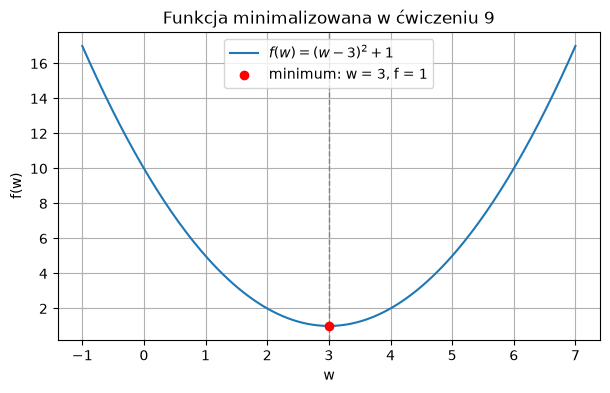

In [35]:
import numpy as np
import matplotlib.pyplot as plt

w = np.linspace(-1, 7, 200)
f = (w - 3)**2 + 1

plt.figure(figsize=(7, 4))
plt.plot(w, f, label='$f(w) = (w - 3)^2 + 1$')
plt.scatter(3, 1, color='red', zorder=3, label='minimum: w = 3, f = 1')
plt.axvline(3, color='gray', linestyle='--', linewidth=1)
plt.xlabel('w')
plt.ylabel('f(w)')
plt.title('Funkcja minimalizowana w ćwiczeniu 9')
plt.legend()
plt.grid(True)
plt.show()

### Ćwiczenie 8
Zbiór treningowy ma `n` obserwacji, a model uczymy z paczkami (`batch_size`) przez `epochs` epok.

Policz, ile **iteracji (aktualizacji wag)** przypada na jedną epokę i ile na cały trening. Pamiętaj, że ostatnia paczka może być niepełna. Wydrukuj obie liczby w osobnych liniach.

__Oczekiwany wynik:__

```
1719
25785
```

__Wskazówka:__ Zaokrąglenie w górę: `np.ceil`.

In [36]:
n = 55000
batch_size = 32
epochs = 15

In [37]:
iterations_per_epoch = int(np.ceil(n / batch_size))
print(iterations_per_epoch)
print(iterations_per_epoch * epochs)

1719
25785
